In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

## Data loading

In [2]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
rhuh_dir = "Glioblastoma_RHUH-GBM_v2-29102025"
tcga_dir = "Glioblastoma_TCGA-GBM_v1-20170717"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1, 2, 3]
n_jobs = 16
nthreads = 2

DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

rhuh_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==2]["ID"].values]
rhuh_ids = [sub.replace('-0', '-', 1) for sub in rhuh_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{rhuh_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(rhuh_ids, desc="Loading RHUH maps")
)
maps_rhuh = np.vstack(results) # Nsubjects x nFeatures
maps_rhuh = np.where(maps_rhuh>=0, maps_rhuh, 0)

def delete_second_zero(text):
    splits = text.split('-')
    if len(splits) >= 3 and splits[2].startswith('0'):
        splits[2] = splits[2][1:]
    return '-'.join(splits)

tcga_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==3]["ID"].values]
tcga_ids = [delete_second_zero(sub) for sub in tcga_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{tcga_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(tcga_ids, desc="Loading TCGA maps")
)
maps_tcga = np.vstack(results)
maps_tcga = np.where(maps_tcga>=0, maps_tcga, 0)

maps_all = np.vstack((maps_ucsf, maps_upenn, maps_rhuh, maps_tcga))

maps_training = np.vstack((maps_ucsf, maps_upenn))
maps_testing = np.vstack((maps_rhuh, maps_tcga))

Log-rank test: chi-squared statistic of 0.3129840079623018 (p=0.9575683269152051)
INFO: The effect of site was NOT found to be significant, copying OS data as it was


Loading TCGA maps: 100%|██████████| 103/103 [00:00<00:00, 129.16it/s]


In [4]:
np.isclose(maps_training, 0)

array([[ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       ...,
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True]])

## Datasets

In [6]:
from dataset import Dataset
from transformer import Transformer, Projector
from lifelines import CoxPHFitter
    
import matplotlib.pyplot as plt
from pipeline_encoder import EncodingPipeline
from results_saving import save_results

In [7]:
UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1
RHUH_SITE_IDX = 3
TCGA_SITE_IDX = 2

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()
data_rhuh = DATA[DATA['site'] == RHUH_SITE_IDX].copy()
data_tcga = DATA[DATA['site'] == TCGA_SITE_IDX].copy()

data_training = pd.concat([data_ucsf, data_upenn], ignore_index=True)
data_testing = pd.concat([data_rhuh, data_tcga], ignore_index=True)

dataset_training = Dataset("ucsf+upenn", "path/1", maps_training, data_training)
dataset_testing = Dataset("rhuh+tcga", "path/2", maps_testing, data_testing)

df_training = dataset_training.df
df_testing = dataset_testing.df
training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

In [8]:
duration_col = 'OS (corrected)'
event_col = 'status'

## Execute feature extraction method

In [9]:
from KernelPCA import TD_Kernel_PCA
from TractDensityComponents import TD_PCA


normalization = None
n_components= 100

method = TD_PCA(maps_training, T1, binary_mask=T1_brain, n_components=n_components)
trainer = Transformer(method)
comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

: 

### Prepare data

In [7]:
from data_transformer import DataTransformer


df_base = df_training
df_base = df_base.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_training, method, n_components=n_components)
encoding_pipeline = EncodingPipeline(X_train_with_features)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_testing, method, n_components=n_components)
X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

In [31]:
# prefix = "PCA_Comp_"
# raw_components = [col for col in X_train.columns if col.startswith(prefix)]
# correlations = X_train[raw_components].corrwith(X_train[duration_col])
# correlations.abs().sort_values(ascending=False).index.tolist()[0:10]

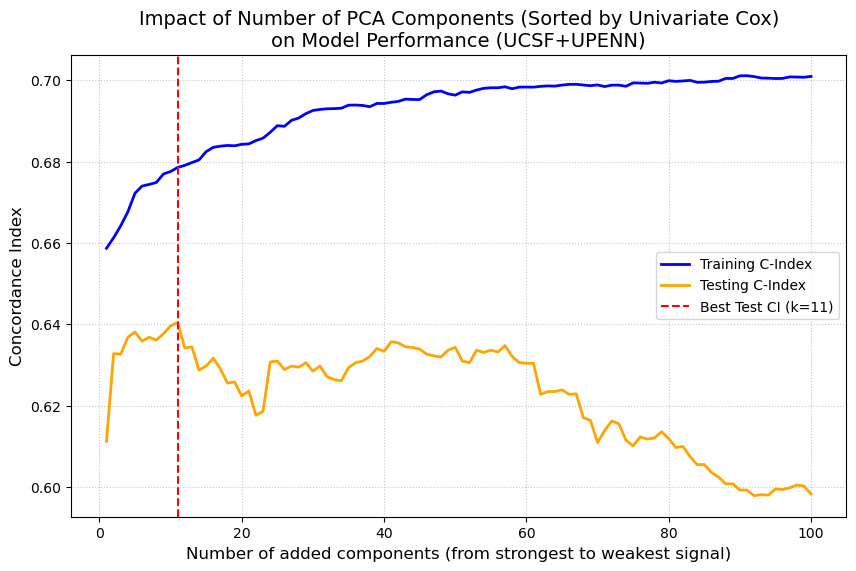

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter


prefix = "PCA_Comp_"
raw_components = [col for col in X_train.columns if col.startswith(prefix)]

component_scores = {}

for comp in raw_components:
    # Create a subset with a single feature, time, and EVENT (censoring)
    df_subset = X_train[[comp, duration_col, event_col]]
    
    # Train a simple Cox model with a light numerical penalty
    cph_uni = CoxPHFitter(penalizer=0)
    
    try:
        cph_uni.fit(df_subset, duration_col, event_col)
        # Calculate power: distance of C-Index from random guessing (0.5)
        power = abs(cph_uni.concordance_index_ - 0.5)
        component_scores[comp] = power
    except Exception as e:
        print(f"Skipped {comp} due to error: {e}")
        component_scores[comp] = 0.0 # Failed components receive zero power

# Sort from strongest to weakest
components_sorted_by_power = sorted(component_scores, key=component_scores.get, reverse=True)

# print("\nTop 5 components with the highest predictive power (distance from 0.5):")
# for comp in components_sorted_by_power[:5]:
#     print(f"{comp}: {component_scores[comp]:.4f}")

# Extract clinical columns (everything that is not a component or target)
clinical_columns = [col for col in X_train.columns if col not in raw_components and col not in [duration_col, event_col]]

# =========================================================
# MAIN INCREMENTAL LOOP
# =========================================================
history_k = []
history_train_ci = []
history_test_ci = []

# The loop iterates over our medically correct, sorted list
for k in range(1, len(components_sorted_by_power) + 1):
    
    # Take the top k most important components
    current_features = components_sorted_by_power[:k]
    
    # Concatenate all required columns
    selected_features = clinical_columns + current_features + [duration_col, event_col]
    
    # Extract subsets for training and testing
    X_train_subset = X_train[selected_features]
    X_test_subset = X_test[selected_features]
    
    # Initialize the main model (with L2 penalty for stability)
    cph = CoxPHFitter(penalizer=0.501, l1_ratio=0.501)
    
    try:
        cph.fit(X_train_subset, duration_col, event_col)
    except Exception as e:
        print(f"Fitting error for k={k} components: {e}")
        continue
        
    # Model evaluation
    train_c_index = cph.concordance_index_
    c_index_test = cph.score(X_test_subset, "concordance_index")
    
    # Save history for plotting
    history_k.append(k)
    history_train_ci.append(train_c_index)
    history_test_ci.append(c_index_test)

    # Prepare results for CSV export
    results = {
        "extraction_method": "PCA-Univariate-Cox-Sorted", 
        "training_dataset": dataset_training.name,
        "testing_dataset": dataset_testing.name,
        "n_pca_components": k,  
        "cox_method": "CoxPHFitter (Incremental)",
        "ci_training": round(train_c_index, 5),
        "ci_testing": round(c_index_test, 5),
        "covariates": clinical_columns + current_features,
        "duration_col": duration_col,
        "event_col": event_col
    }
    save_results(results, "results-incremental/pca_incremental_lifelines.csv")
    
    # print(f"Added components: {k:03d} (last: {current_features[-1]}) | Train CI: {train_c_index:.4f} | Test CI: {c_index_test:.4f}")


if history_k:
    plt.figure(figsize=(10, 6))
    plt.plot(history_k, history_train_ci, label='Training C-Index', color='blue', linewidth=2)
    plt.plot(history_k, history_test_ci, label='Testing C-Index', color='orange', linewidth=2)
    
    plt.title(f"Impact of Number of PCA Components (Sorted by Univariate Cox)\non Model Performance ({dataset_training.name.upper()})", fontsize=14)
    plt.xlabel("Number of added components (from strongest to weakest signal)", fontsize=12)
    plt.ylabel("Concordance Index", fontsize=12)
    
    best_k_idx = np.argmax(history_test_ci)
    plt.axvline(x=history_k[best_k_idx], color='red', linestyle='--', 
                label=f'Best Test CI (k={history_k[best_k_idx]})')
    
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.7)
    
    plt.savefig("results-incremental/pca_incremental_curve.png", bbox_inches='tight')
    plt.show()

In [10]:
current_features = components_sorted_by_power[:11]
clinical_columns = [col for col in X_train.columns if col not in raw_components and col not in [duration_col, event_col]]

selected_features = clinical_columns + current_features + [duration_col, event_col]
X_train_subset = X_train[selected_features]

cph = CoxPHFitter(penalizer=0.01)
cph.fit(X_train_subset, duration_col, event_col)

<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>

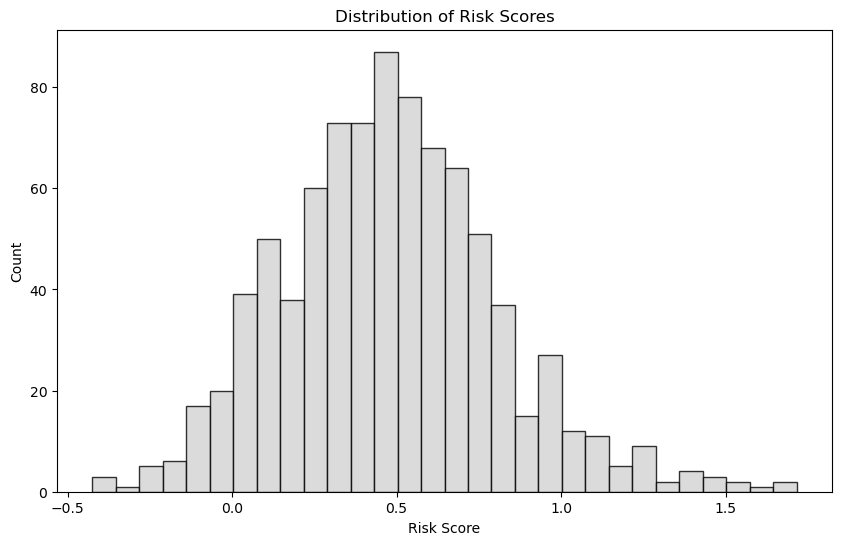

Running Log-Rank tests for extreme percentiles...
Bottom 5% vs Top 5% -> p-value: 0.00000
Bottom 10% vs Top 10% -> p-value: 0.00000
Bottom 15% vs Top 15% -> p-value: 0.00000
Bottom 20% vs Top 20% -> p-value: 0.00000
Bottom 25% vs Top 25% -> p-value: 0.00000
Bottom 30% vs Top 30% -> p-value: 0.00000
Bottom 35% vs Top 35% -> p-value: 0.00000
Bottom 40% vs Top 40% -> p-value: 0.00000
Bottom 45% vs Top 45% -> p-value: 0.00000
Bottom 50% vs Top 50% -> p-value: 0.00000


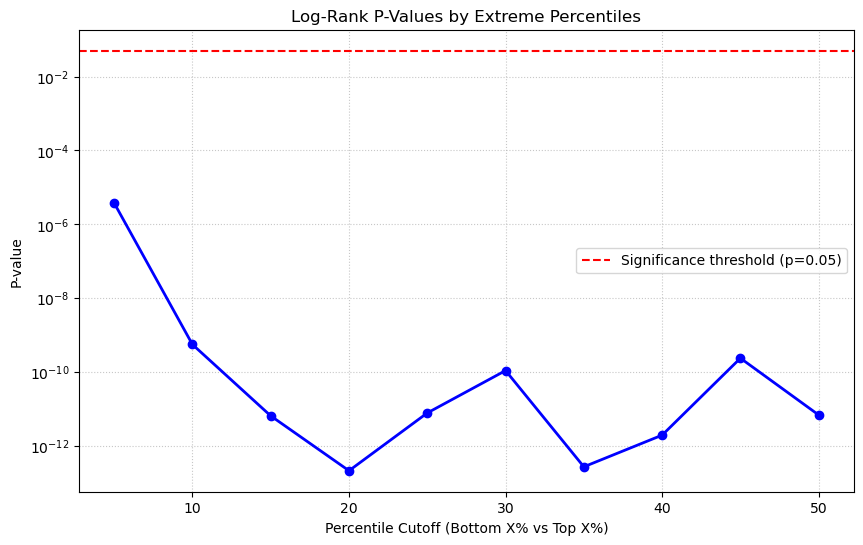

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import lifelines

# 1. Safely extract weights (as discussed previously!)
betas_PCs = cph.params_[current_features].values
PCs = X_train[current_features].values
PCS_test = X_test[current_features].values

risk_scores = np.dot(PCs, betas_PCs)
risk_scores_test = np.dot(PCS_test, betas_PCs)

# 2. Plot Histogram FIRST
plt.figure(figsize=(10, 6))
plt.hist(risk_scores, bins=30, color='lightgray', edgecolor='black', alpha=0.8)
plt.title("Distribution of Risk Scores")
plt.xlabel("Risk Score")
plt.ylabel("Count")
plt.show() # <-- Show it and move on

# 3. Start at 5 to prevent empty arrays!
ps = np.arange(5, 51, 5)
pvalues = []

print("Running Log-Rank tests for extreme percentiles...")

for p in ps:
    # This compares extreme tails (e.g., bottom 20% vs top 20%)
    low_risk = risk_scores < np.percentile(risk_scores, p)
    high_risk = risk_scores >= np.percentile(risk_scores, 100 - p)
    
    # We wrap in try-except just in case a specific split fails numerically
    try:
        logrank_result = lifelines.statistics.logrank_test(
            df_training[low_risk][duration_col],
            df_training[high_risk][duration_col],
            event_observed_A=df_training[low_risk][event_col],
            event_observed_B=df_training[high_risk][event_col]
        )
        p_value = logrank_result.p_value
    except Exception as e:
        print(f"Skipped p={p} due to error: {e}")
        p_value = np.nan # Assign NaN if the test fails

    pvalues.append(p_value)
    print(f"Bottom {p}% vs Top {p}% -> p-value: {p_value:.5f}")

# 4. Plot P-values LAST
plt.figure(figsize=(10, 6))
plt.plot(ps, pvalues, marker='o', linestyle='-', color='blue', linewidth=2)

# Add a red dashed line at 0.05 to easily see what is statistically significant
plt.axhline(y=0.05, color='red', linestyle='--', label='Significance threshold (p=0.05)')

plt.title("Log-Rank P-Values by Extreme Percentiles")
plt.xlabel("Percentile Cutoff (Bottom X% vs Top X%)")
plt.ylabel("P-value")
plt.yscale('log') # Log scale is often much better for visualizing p-values!
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

The exact p-value is: nan


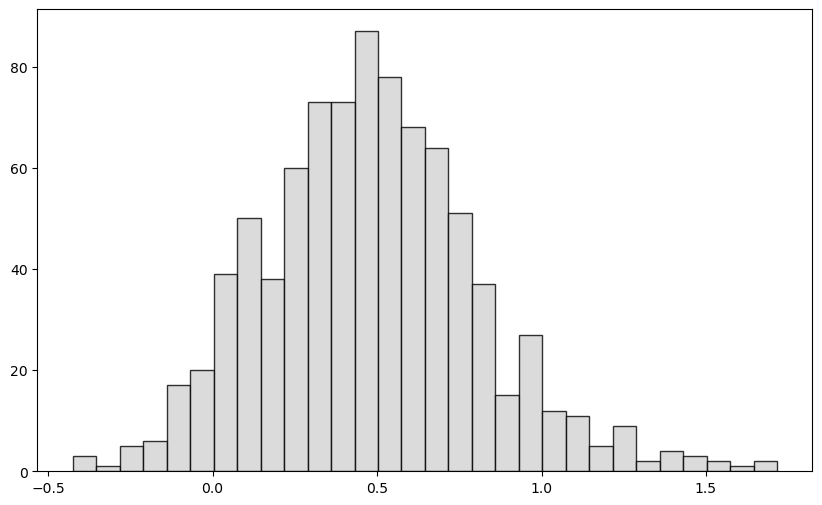

The exact p-value is: 3.7437668933840936e-06
The exact p-value is: 5.497453264969809e-10
The exact p-value is: 6.397960808799932e-12
The exact p-value is: 2.0873300560981325e-13
The exact p-value is: 7.664562448796156e-12
The exact p-value is: 1.0788886060426773e-10
The exact p-value is: 2.6652768441187563e-13
The exact p-value is: 1.9212398152819993e-12
The exact p-value is: 2.3373961301535673e-10
The exact p-value is: 6.755438918371839e-12
The exact p-value is: 8.36205580479426e-09
The exact p-value is: 8.170699269943548e-09
The exact p-value is: 3.229978714336653e-08
The exact p-value is: 8.645260247691459e-06
The exact p-value is: 4.4578984249980535e-05
The exact p-value is: 0.00016158574159226175
The exact p-value is: 0.0036544895482144017
The exact p-value is: 0.033268812254544276
The exact p-value is: 0.3331730870051949
The exact p-value is: 0.9792701007002728


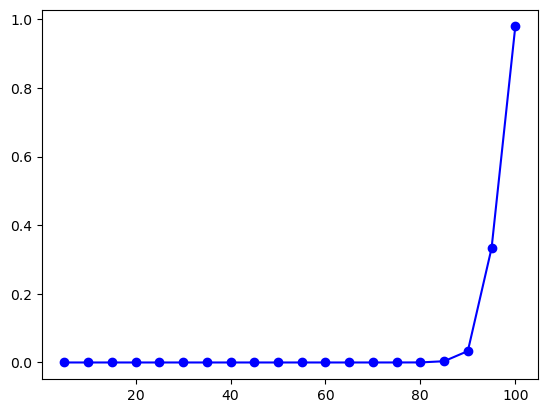

In [15]:
import matplotlib.pyplot as plt
import numpy as np


from lifelines import KaplanMeierFitter
import lifelines

betas_PCs = cph.params_[4:].values
PCs = X_train[current_features].values
PCS_test = X_test[current_features].values
risk_scores = np.dot(PCs, betas_PCs)
risk_scores_test = np.dot(PCS_test, betas_PCs)

plt.figure(figsize=(10, 6))
plt.hist(risk_scores, bins=30, color='lightgray', edgecolor='black', alpha=0.8)

ps = np.arange(0, 101, 5)
pvalues = []
for p in ps:
    low_risk = risk_scores < np.percentile(risk_scores, p)
    high_risk = risk_scores >= np.percentile(risk_scores, 100-p)
    low_risk_test = risk_scores_test < np.percentile(risk_scores, p)
    high_risk_test = risk_scores_test >= np.percentile(risk_scores, 100-p)


    logrank_result = lifelines.statistics.logrank_test(
        df_training[low_risk][duration_col],
        df_training[high_risk][duration_col],
        event_observed_A=df_training[low_risk][event_col],
        event_observed_B=df_training[high_risk][event_col]
    )
    p_value = logrank_result.p_value

    pvalues.append(p_value)
    print(f"The exact p-value is: {p_value}")

    plt.show()

plt.plot(ps, pvalues, marker='o', linestyle='-', color='blue')

Calculating p-values for different thresholds...
The most statistically significant split is at p=20 (vs 80) with p-value = 0.00000


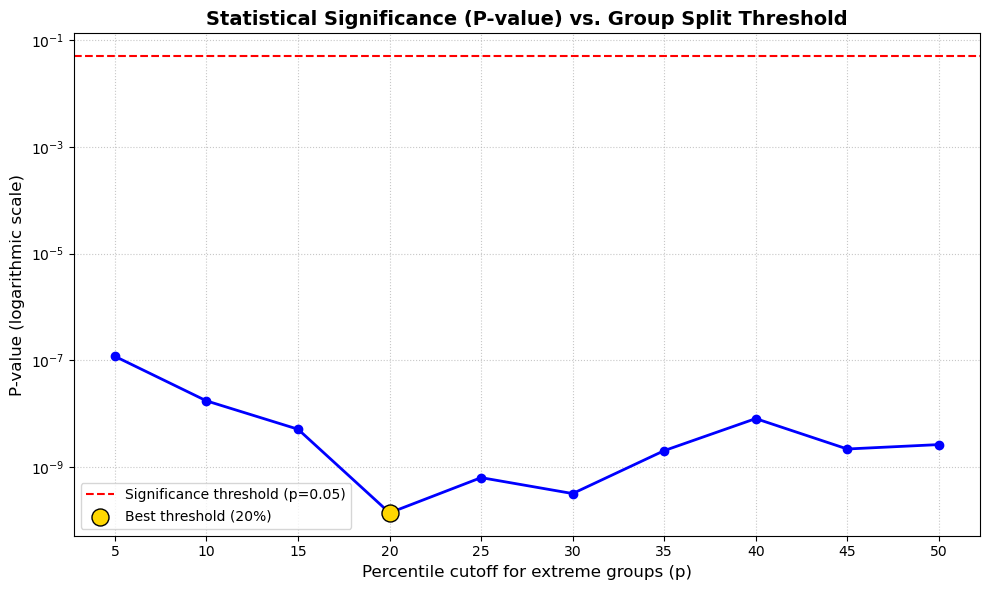

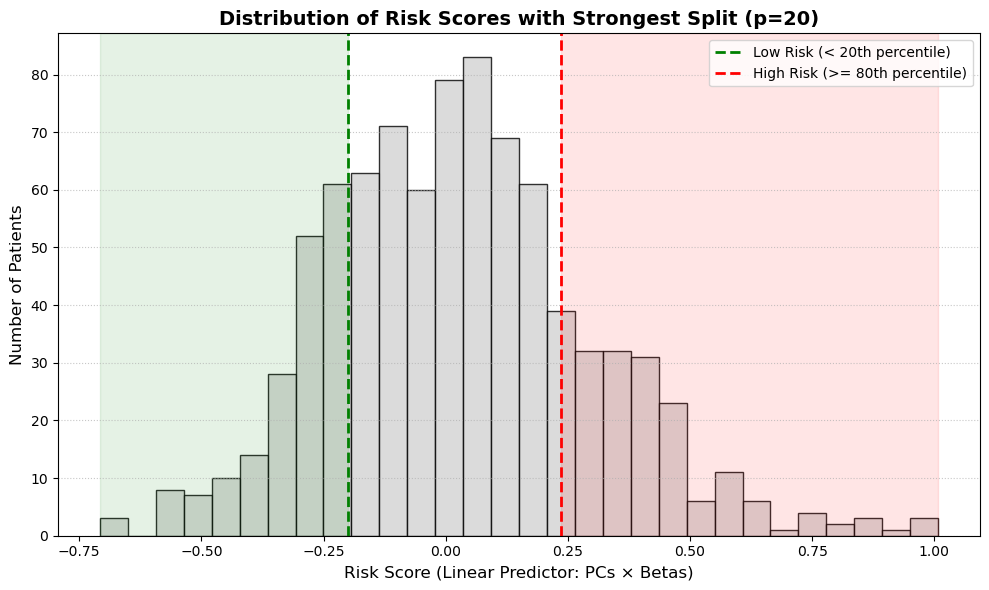

In [36]:
import matplotlib.pyplot as plt
import numpy as np
from lifelines import KaplanMeierFitter
import lifelines

# Calculating Risk Scores
betas_PCs = cph.params_[4:].values
PCs = X_train[current_features].values
PCS_test = X_test[current_features].values
risk_scores = np.dot(PCs, betas_PCs)
risk_scores_test = np.dot(PCS_test, betas_PCs)

# 1. LOOP SETUP: Checking symmetric extremes (from 5% to 50% - up to the median)
ps = np.arange(5, 51, 5) 
pvalues = []

print("Calculating p-values for different thresholds...")

for p in ps:
    # Defining thresholds for a given p
    thresh_low = np.percentile(risk_scores, p)
    thresh_high = np.percentile(risk_scores, 100-p)
    
    # Splitting into groups
    low_risk = risk_scores < thresh_low
    high_risk = risk_scores >= thresh_high
    
    # Log-rank test
    logrank_result = lifelines.statistics.logrank_test(
        df_training[low_risk][duration_col],
        df_training[high_risk][duration_col],
        event_observed_A=df_training[low_risk][event_col],
        event_observed_B=df_training[high_risk][event_col]
    )
    p_value = logrank_result.p_value
    pvalues.append(p_value)

# Finding the "best" p (lowest p-value) to plot on the histogram
best_p_idx = np.argmin(pvalues)
best_p = ps[best_p_idx]
best_thresh_low = np.percentile(risk_scores, best_p)
best_thresh_high = np.percentile(risk_scores, 100-best_p)

print(f"The most statistically significant split is at p={best_p} (vs {100-best_p}) with p-value = {pvalues[best_p_idx]:.5f}")

# =========================================================
# PLOT 1: P-value vs Cutoff Threshold (Logarithmic Scale)
# =========================================================
plt.figure(figsize=(10, 6))
plt.plot(ps, pvalues, marker='o', linestyle='-', color='blue', linewidth=2)

# Set Y-axis to logarithmic scale
plt.yscale('log')

# Red line for the significance threshold (0.05)
plt.axhline(y=0.05, color='red', linestyle='--', label='Significance threshold (p=0.05)')

# Highlight the best result with a gold dot
plt.scatter(best_p, pvalues[best_p_idx], color='gold', s=150, zorder=5, edgecolor='black', label=f'Best threshold ({best_p}%)')

plt.title('Statistical Significance (P-value) vs. Group Split Threshold', fontsize=14, fontweight='bold')
plt.xlabel('Percentile cutoff for extreme groups (p)', fontsize=12)
plt.ylabel('P-value (logarithmic scale)', fontsize=12)
plt.xticks(ps)
plt.grid(True, which="both", linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

# =========================================================
# PLOT 2: Risk Scores Histogram with the Best Cutoff
# =========================================================
plt.figure(figsize=(10, 6))
plt.hist(risk_scores, bins=30, color='lightgray', edgecolor='black', alpha=0.8)

# Lines for the BEST found threshold
plt.axvline(best_thresh_low, color='green', linestyle='--', linewidth=2, 
            label=f'Low Risk (< {best_p}th percentile)')
plt.axvline(best_thresh_high, color='red', linestyle='--', linewidth=2, 
            label=f'High Risk (>= {100-best_p}th percentile)')

# Shade the risk zones
plt.axvspan(risk_scores.min(), best_thresh_low, color='green', alpha=0.1)
plt.axvspan(best_thresh_high, risk_scores.max(), color='red', alpha=0.1)

plt.title(f'Distribution of Risk Scores with Strongest Split (p={best_p})', fontsize=14, fontweight='bold')
plt.xlabel('Risk Score (Linear Predictor: PCs × Betas)', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

In [12]:
daysXmonth = 365 / 12
kmf_low.median_survival_time_ #/ daysXmonth, kmf_high.median_survival_time_ / daysXmonth

719.0

In [13]:
kmf_high.confidence_interval_

,High Risk_lower_0.95,High Risk_upper_0.95
0.000000,1.000000,1.000000
4.017894,0.983683,0.999674
10.000000,0.983683,0.999674
14.000000,0.983683,0.999674
15.000000,0.983683,0.999674
...,...,...
2014.303972,0.006210,0.040064
2042.429227,0.003840,0.034306
2495.111901,0.001846,0.028321
3333.512358,0.001846,0.028321


<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic    p  -log2(p)
           0.00 0.95      0.08

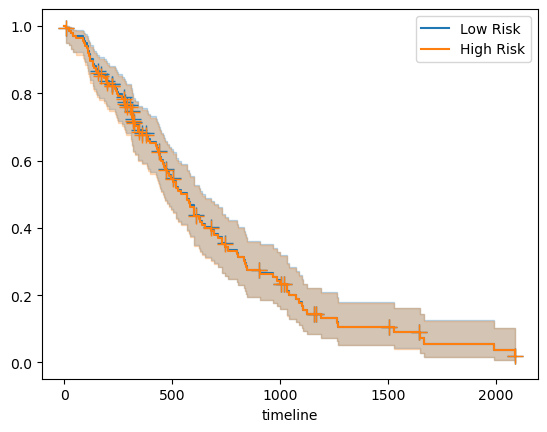

In [37]:
kmf_high_test = KaplanMeierFitter()
kmf_low_test = KaplanMeierFitter()
kmf_low_test.fit(df_testing[low_risk_test][duration_col], event_observed=df_testing[low_risk_test][event_col], label='Low Risk')
kmf_high_test.fit(df_testing[high_risk_test][duration_col], event_observed=df_testing[high_risk_test][event_col], label='High Risk')
kmf_low_test.plot_survival_function(show_censors=True, )
kmf_high_test.plot_survival_function(show_censors=True) 

lifelines.statistics.logrank_test(
    df_testing[low_risk_test][duration_col],
    df_testing[high_risk_test][duration_col],
    event_observed_A=df_testing[low_risk_test][event_col],
    event_observed_B=df_testing[high_risk_test][event_col]
).print_summary()